In [1]:
%load_ext autoreload
%autoreload 2

import os
from pathlib import Path
os.chdir(Path().cwd().parent.parent)

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
from geo6.io.io import load_data
from geo6.config import Config

config = Config()

In [91]:
data = load_data()

In [93]:
microresp = data.microresp

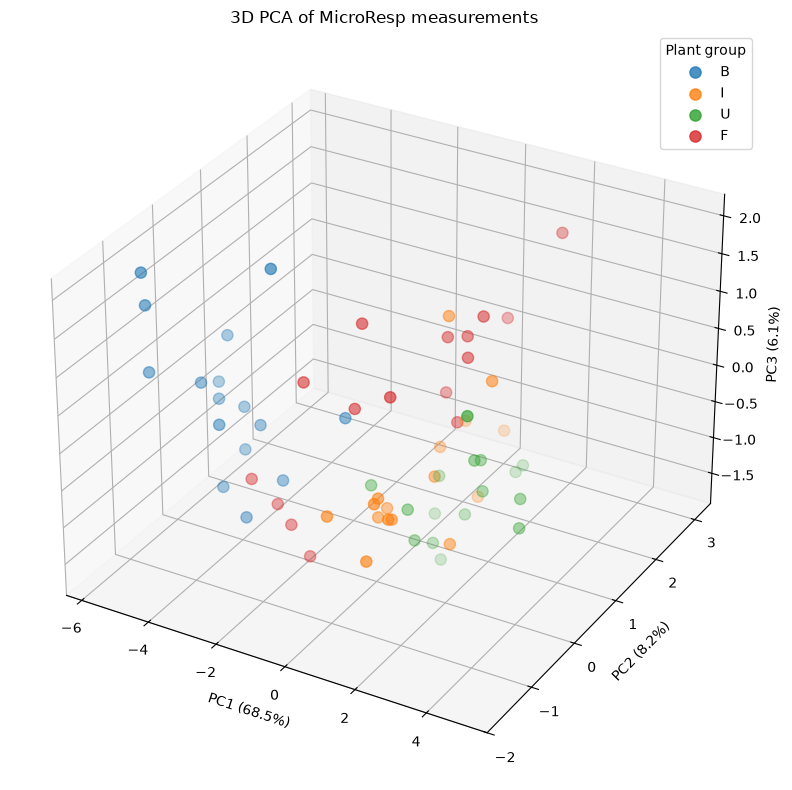

PC1    68.5%
PC2     8.2%
PC3     6.1%
dtype: str
Total variance explained by first 3 PCs: 82.9%


In [95]:
from sklearn.decomposition import PCA
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Select the six MicroResp response variables
features = [
    'br_mg_per_g_h', 'sir_1_mg_per_g_h', 'sir_2_mg_per_g_h',
    'sir_3_mg_per_g_h', 'sir_4_mg_per_g_h', 'sir_5_mg_per_g_h', 
    'sir_6_mg_per_g_h', 'sir_7_mg_per_g_h', 'sir_8_mg_per_g_h',
    'sir_9_mg_per_g_h', 'sir_10_mg_per_g_h', 'sir_11_mg_per_g_h'
]

# Keep only the selected variables and group labels
df_pca = microresp[["sample", *features]].copy()

# Impute missing values with the median of each variable
imputer = SimpleImputer(strategy="median")
X_imputed = imputer.fit_transform(df_pca[features])

# Standardize variables because they have different variances
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_imputed)

# Fit PCA with three components
pca = PCA(n_components=3)
scores = pca.fit_transform(X_scaled)

scores_df = pd.DataFrame(
    scores,
    columns=["PC1", "PC2", "PC3"],
    index=df_pca.index,
)
scores_df["sample"] = df_pca["sample"].values

# 3D scatter plot
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection="3d")

for group in ["B", "I", "U", "F"]:
    mask = scores_df["sample"] == group

    ax.scatter(
        scores_df.loc[mask, "PC1"],
        scores_df.loc[mask, "PC2"],
        scores_df.loc[mask, "PC3"],
        label=group,
        s=65,
        alpha=0.8,
    )

ax.set_xlabel(
    f"PC1 ({pca.explained_variance_ratio_[0]:.1%})"
)
ax.set_ylabel(
    f"PC2 ({pca.explained_variance_ratio_[1]:.1%})"
)
ax.set_zlabel(
    f"PC3 ({pca.explained_variance_ratio_[2]:.1%})"
)

ax.set_title("3D PCA of MicroResp measurements")
ax.legend(title="Plant group")

plt.tight_layout()
plt.show()

# Variance explained by each component
print(
    pd.Series(
        pca.explained_variance_ratio_,
        index=["PC1", "PC2", "PC3"],
    ).map("{:.1%}".format)
)

print(
    f"Total variance explained by first 3 PCs: "
    f"{pca.explained_variance_ratio_.sum():.1%}"
)

In [9]:
copper = data.copper
copper_sub = copper[["sample", "cu_ex_ug_kg_dm", "cu_org_ug_kg_dm", "cu_red_ug_kg_dm"]]


copper_agg = (
    copper_sub
    .groupby("sample")
    .agg(
        ["mean", "std"]
    )
    .reset_index()
)

C:\Users\Administrator\AppData\Local\Temp\ipykernel_6104\2136735052.py:1: PerformanceWarning: dropping on a non-lexsorted multi-index without a level parameter may impact performance.
  data_cols = copper_agg.drop(columns="sample").columns.to_list()


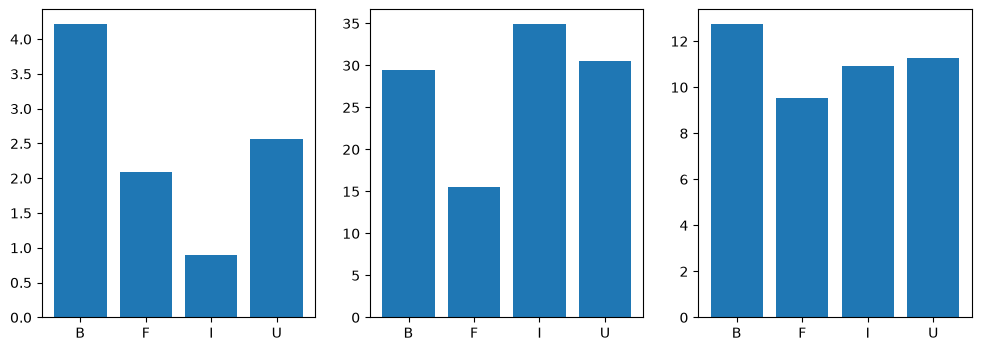

In [40]:
data_cols = copper_agg.drop(columns="sample").columns.to_list()

mean_cols = [col[0] for col in data_cols if col[1] == "mean"]
std_cols = [col[0] for col in data_cols if col[1] == "std"]


fig, axs = plt.subplots(figsize=(12, 4), ncols=3)

for i, col in enumerate(mean_cols):
    
    axs[i].bar(
        x=copper_agg["sample"],
        height=copper_agg[col]["mean"]
    )